# Week 3: Comparing Supervised Learning Models
**Fayz Liaqat | 23 October 2026**

I continue with my Week 2 loan dataset and compare KNN, a Decision Tree, and
Logistic Regression. The aim is to evaluate their predictions, understand
their mistakes, and explain which model I would choose for this exercise.

The opening goal also mentions Linear Regression, so I include it separately
as an extra comparison. The target is categorical, so the three classifiers
are the main models. Linear Regression is not a probability classifier.

**Dataset:** [Loan Predication on Kaggle](https://www.kaggle.com/datasets/ninzaami/loan-predication).
The included raw CSV has 614 data rows and 13 columns. No new download, API
key, or GPU is needed. Run this notebook from the project folder.

**Positive class:** 1 = historically approved. **Negative class:** 0 = historically not approved.
These labels do not tell us whether an applicant would repay a loan.

I use a fixed outer 80/20 split. A smaller validation split inside the
training set chooses the settings, so the final test set does not guide
tuning. One split gives limited evidence; these results are for coursework.

## Step 1: Prepare the data
I check the raw data, remove exact duplicate rows, and drop the application
ID from the inputs. I keep the Week 2 features `totalIncome` and
`hasCoapplicantIncome`. They describe combined income and whether there is
a positive co-applicant income contribution. They do not use the target.

Missing numbers will use training medians. Missing text will use the most
frequent training category. I leave the missing cells untouched until after
splitting, so no fill values are learned from the test set.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, mean_absolute_error,
    mean_squared_error, r2_score
)

projectDir = Path.cwd()
outputDir = projectDir / "outputs"
outputDir.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110

loanData = pd.read_csv(projectDir / "data" / "loan_data.csv")
print("Raw shape:", loanData.shape)
loanData.info()
display(loanData.head())
display(loanData.describe().T)
display(loanData.isna().sum().rename("missingCount").to_frame())
print("Exact duplicate rows:", loanData.duplicated().sum())
loanData = loanData.drop_duplicates().copy()

loanData = loanData.rename(columns={
    "Loan_ID": "loanId", "Gender": "gender", "Married": "married",
    "Dependents": "dependents", "Education": "education",
    "Self_Employed": "selfEmployed", "ApplicantIncome": "applicantIncome",
    "CoapplicantIncome": "coapplicantIncome", "LoanAmount": "loanAmount",
    "Loan_Amount_Term": "loanTerm", "Credit_History": "creditHistory",
    "Property_Area": "propertyArea", "Loan_Status": "loanStatus"
})
print("Missing targets:", loanData["loanStatus"].isna().sum())
loanData = loanData.dropna(subset=["loanStatus"]).copy()
assert loanData[["applicantIncome", "coapplicantIncome"]].notna().all().all()
loanData["totalIncome"] = loanData["applicantIncome"] + loanData["coapplicantIncome"]
loanData["hasCoapplicantIncome"] = (loanData["coapplicantIncome"] > 0).astype(int)

features = loanData.drop(columns=["loanId", "loanStatus"])
target = loanData["loanStatus"].map({"N": 0, "Y": 1})
assert target.notna().all()

Raw shape: (614, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,146.412162,85.587325,9.0,100.0,128.0,168.00,700.0
Loan_Amount_Term,600.0,342.000000,65.120410,12.0,360.0,360.0,360.00,480.0
Credit_History,564.0,0.842199,0.364878,0.0,1.0,1.0,1.00,1.0


,missingCount
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


Exact duplicate rows: 0
Missing targets: 0


### Class balance
I count both target classes before training. Approved applications are more
common, so a model can get a reasonable-looking accuracy by always choosing
that class. Later I compare accuracy with per-class F1 and macro-F1.

,count,percent
loanStatus,,
0,192,31.27
1,422,68.73


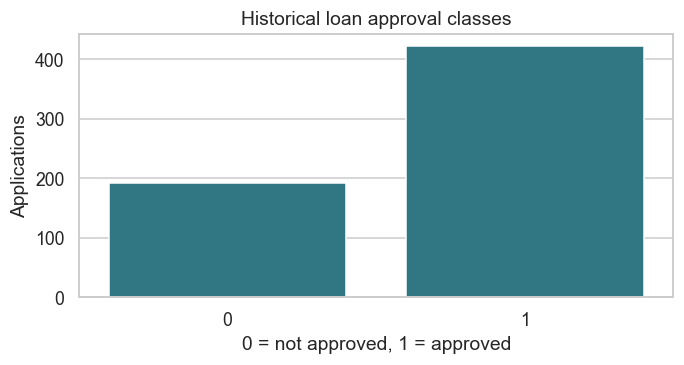

In [2]:
classBalance = pd.DataFrame({
    "count": target.value_counts().sort_index(),
    "percent": target.value_counts(normalize=True).sort_index().mul(100).round(2)
})
display(classBalance)
classBalance.to_csv(outputDir / "class_balance.csv", index_label="target")

plt.figure(figsize=(6.4, 3.5))
sns.countplot(x=target, order=[0, 1], color="#237F91")
plt.title("Historical loan approval classes")
plt.xlabel("0 = not approved, 1 = approved")
plt.ylabel("Applications")
plt.tight_layout()
plt.savefig(outputDir / "class_balance.png", dpi=180)
plt.show()
plt.close()

### Split before learning any preprocessing values
The outer split uses `test_size=0.20`, `stratify=target`, and
`random_state=42`: 491 training rows and 123 test rows.
I split only the 491 training rows again into 392 tuning rows and 99
validation rows. Validation accuracy chooses K and tree depth, as requested.
Validation macro-F1 chooses between the three model families because it
gives both classes equal weight. Ties favor higher approval precision,
then higher accuracy. A complete tie keeps the first listed model.

The test set stays untouched until the settings and chosen family are fixed.

In [3]:
trainInputs, testInputs, trainTarget, testTarget = train_test_split(
    features, target, test_size=0.20, random_state=42, stratify=target
)
tuningInputs, validationInputs, tuningTarget, validationTarget = train_test_split(
    trainInputs, trainTarget, test_size=0.20, random_state=42, stratify=trainTarget
)

splitSummary = pd.DataFrame({
    "rows": [len(tuningTarget), len(validationTarget), len(trainTarget), len(testTarget)],
    "approvedPercent": [
        tuningTarget.mean() * 100, validationTarget.mean() * 100,
        trainTarget.mean() * 100, testTarget.mean() * 100
    ]
}, index=["tuning", "validation", "full training", "test"])
display(splitSummary.round(2))

assert set(trainInputs.index).isdisjoint(testInputs.index)
assert set(tuningInputs.index).isdisjoint(validationInputs.index)

,rows,approvedPercent
tuning,392,68.62
validation,99,68.69
full training,491,68.64
test,123,69.11


### Impute, encode, and scale
I combine numeric and categorical pipelines with `ColumnTransformer`.
Numbers use median filling followed by `StandardScaler`; text uses mode
filling followed by `OneHotEncoder`. `dependents` stays categorical because
`3+` is a category. The binary `creditHistory` follows the numeric rule.

For tuning, `fit_transform` sees only the 392 tuning rows. Validation uses
only `transform`. After model selection, I create a fresh preprocessor and
fit it on all 491 training rows. The final test data receives only `transform`.
The one-hot columns remain 0/1, while numeric columns are standardized.

In [4]:
numericColumns = trainInputs.select_dtypes(include="number").columns.tolist()
categoricalColumns = trainInputs.select_dtypes(include="object").columns.tolist()

def makePreprocessor():
    numericPipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categoricalPipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("numeric", numericPipeline, numericColumns),
        ("categorical", categoricalPipeline, categoricalColumns)
    ])

tuningPreprocessor = makePreprocessor()
scaledTuningInputs = tuningPreprocessor.fit_transform(tuningInputs)
scaledValidationInputs = tuningPreprocessor.transform(validationInputs)
print("Numeric columns:", numericColumns)
print("Categorical columns:", categoricalColumns)
print("Tuning shape:", scaledTuningInputs.shape)
print("Validation shape:", scaledValidationInputs.shape)
assert np.isfinite(scaledTuningInputs).all()
assert np.isfinite(scaledValidationInputs).all()

Numeric columns: ['applicantIncome', 'coapplicantIncome', 'loanAmount', 'loanTerm', 'creditHistory', 'totalIncome', 'hasCoapplicantIncome']
Categorical columns: ['gender', 'married', 'dependents', 'education', 'selfEmployed', 'propertyArea']
Tuning shape: (392, 22)
Validation shape: (99, 22)


## Step 2: K-Nearest Neighbors
I first train the required `KNeighborsClassifier(n_neighbors=5)`.
Then I try odd K values from 1 to 15. The chart uses validation accuracy,
not test accuracy. I choose the highest validation accuracy; a tie keeps
the smaller K because the values are checked in ascending order.

K = 5 validation accuracy: 0.8181818181818182


,k,validationAccuracy
0,1,0.737374
1,3,0.747475
2,5,0.818182
3,7,0.808081
4,9,0.808081
5,11,0.808081
6,13,0.797980
7,15,0.797980


Chosen K: 5


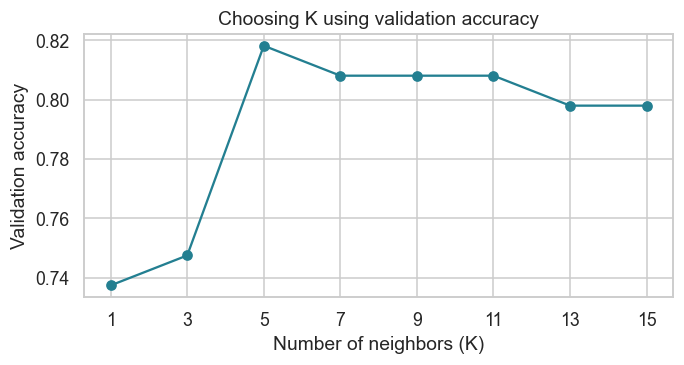

In [5]:
knnFive = KNeighborsClassifier(n_neighbors=5)
knnFive.fit(scaledTuningInputs, tuningTarget)
print("K = 5 validation accuracy:", accuracy_score(
    validationTarget, knnFive.predict(scaledValidationInputs)
))

knnResults = []
for kValue in range(1, 16, 2):
    knnCandidate = KNeighborsClassifier(n_neighbors=kValue)
    knnCandidate.fit(scaledTuningInputs, tuningTarget)
    knnResults.append({
        "k": kValue,
        "validationAccuracy": accuracy_score(
            validationTarget, knnCandidate.predict(scaledValidationInputs)
        )
    })
knnResults = pd.DataFrame(knnResults)
bestK = int(knnResults.loc[knnResults["validationAccuracy"].idxmax(), "k"])
display(knnResults)
print("Chosen K:", bestK)
knnResults.to_csv(outputDir / "knn_tuning.csv", index=False)

plt.figure(figsize=(6.4, 3.5))
plt.plot(knnResults["k"], knnResults["validationAccuracy"], marker="o", color="#237F91")
plt.xticks(list(range(1, 16, 2)))
plt.title("Choosing K using validation accuracy")
plt.xlabel("Number of neighbors (K)")
plt.ylabel("Validation accuracy")
plt.tight_layout()
plt.savefig(outputDir / "knn_accuracy.png", dpi=180)
plt.show()
plt.close()

## Step 3: Decision Tree
I compare depths 2, 3, 5, 10, and `None`. `None` allows the tree to grow
until its stopping rules are met. Each tree uses `random_state=42`.
I choose the highest validation accuracy; a tie keeps the shallower tree.

I also record training accuracy. A very deep tree can memorize training
examples. A large gap between training and validation accuracy suggests
overfitting, although one split does not prove how well it will generalize.

,maxDepth,actualDepth,trainingAccuracy,validationAccuracy
0,2,2,0.813776,0.787879
1,3,3,0.813776,0.787879
2,5,5,0.829082,0.787879
3,10,10,0.964286,0.747475
4,None,14,1.000000,0.757576


Chosen max_depth: 2


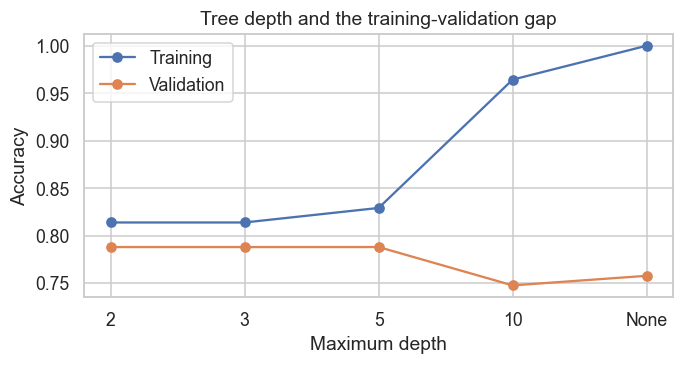

In [6]:
depthValues = [2, 3, 5, 10, None]
treeResults = []
for depthValue in depthValues:
    treeCandidate = DecisionTreeClassifier(max_depth=depthValue, random_state=42)
    treeCandidate.fit(scaledTuningInputs, tuningTarget)
    treeResults.append({
        "maxDepth": str(depthValue),
        "actualDepth": treeCandidate.get_depth(),
        "trainingAccuracy": accuracy_score(
            tuningTarget, treeCandidate.predict(scaledTuningInputs)
        ),
        "validationAccuracy": accuracy_score(
            validationTarget, treeCandidate.predict(scaledValidationInputs)
        )
    })
treeResults = pd.DataFrame(treeResults)
bestDepthIndex = treeResults["validationAccuracy"].idxmax()
bestDepth = depthValues[bestDepthIndex]
display(treeResults)
print("Chosen max_depth:", bestDepth)
treeResults.to_csv(outputDir / "tree_tuning.csv", index=False)

plt.figure(figsize=(6.4, 3.5))
plt.plot(treeResults["maxDepth"], treeResults["trainingAccuracy"], marker="o", label="Training")
plt.plot(treeResults["maxDepth"], treeResults["validationAccuracy"], marker="o", label="Validation")
plt.title("Tree depth and the training-validation gap")
plt.xlabel("Maximum depth")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(outputDir / "tree_depth_accuracy.png", dpi=180)
plt.show()
plt.close()

## Step 4: Logistic Regression and model selection
Logistic Regression is a classifier despite its name. It estimates the
probability of each class. I use `max_iter=1000` to give the solver enough
iterations. The required five test-row probabilities are printed after
the final refit in Step 5, when the test set is first evaluated.

I compare the three tuned model families on validation data. Macro-F1
averages the two class F1-scores equally, so minority-class mistakes still
matter. Accuracy tunes K and depth; macro-F1 selects the model family.
The chosen family is fixed before looking at any test performance.

In [7]:
def calculateScores(modelName, actualTarget, predictedTarget):
    return {
        "Model": modelName,
        "Accuracy": accuracy_score(actualTarget, predictedTarget),
        "Precision": precision_score(actualTarget, predictedTarget, zero_division=0),
        "Recall": recall_score(actualTarget, predictedTarget, zero_division=0),
        "F1": f1_score(actualTarget, predictedTarget, zero_division=0),
        "Macro F1": f1_score(actualTarget, predictedTarget, average="macro", zero_division=0)
    }

candidateModels = {
    "KNN": KNeighborsClassifier(n_neighbors=bestK),
    "Decision Tree": DecisionTreeClassifier(max_depth=bestDepth, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42)
}
validationResults = []
for modelName, candidateModel in candidateModels.items():
    candidateModel.fit(scaledTuningInputs, tuningTarget)
    validationPredictions = candidateModel.predict(scaledValidationInputs)
    validationResults.append(calculateScores(modelName, validationTarget, validationPredictions))
validationResults = pd.DataFrame(validationResults)
rankedValidation = validationResults.sort_values(
    ["Macro F1", "Precision", "Accuracy"], ascending=False, kind="stable"
)
bestModelName = rankedValidation.iloc[0]["Model"]
display(validationResults.round(4))
print("Model selected before test evaluation:", bestModelName)
validationResults.to_csv(outputDir / "validation_comparison.csv", index=False)

,Model,Accuracy,Precision,Recall,F1,Macro F1
0,KNN,0.8182,0.7976,0.9853,0.8816,0.7451
1,Decision Tree,0.7879,0.7765,0.9706,0.8627,0.6980
2,Logistic Regression,0.7879,0.7765,0.9706,0.8627,0.6980


Model selected before test evaluation: KNN
